# DT-assisted beamforming — Étapes 1 et 2 : séquence longue, jumeau par frame et canal réel

**Projet :** *Digital Twin assisted beamforming design* (suite de SDM-VA-ISAC, phases 2 à 5)
**Scène réelle :** `Scene_reelle/real.xml` = `phase3/new.xml` + nouveaux acteurs, mobilier urbain et matériaux perturbés
**Séquence :** 100 frames × 0,1 s = 10 s

| Étape | Module | Question | Script |
|---|---|---|---|
| 1 | M1 | Que voit le jumeau de la phase 5 à chaque frame, sur une séquence longue et multi-acteurs ? | `code/etape1_jumeau_sequence.py` |
| 2 | M6 | Quel est le vrai canal FR2 et le vrai meilleur faisceau pour chaque couple BS–UE ? | `code/etape2_canal_reel.py` |

Ce notebook **lit les résultats** des deux scripts (il ne relance aucun lancer de rayons) ;
il s'exécute en quelques secondes. La dernière partie relie les deux étapes : quel faisceau
obtiendrait-on en pointant vers la position **estimée par le jumeau** plutôt que vers la vraie position ?

## 0. Chargement des résultats

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "etape2").exists():
    ROOT = ROOT.parent
E1, E2 = ROOT / "etape1", ROOT / "etape2"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110})
pd.set_option("display.precision", 2)

R2 = np.load(E2 / "canal_reel_fr2.npz", allow_pickle=True)
S2 = json.load(open(E2 / "etape2_summary.json", encoding="utf-8"))
G = R2["G"]                                   # [T, BS, UE, 256] gain moyen sur la bande de chaque faisceau
T, NB, U, B = G.shape
BS = list(R2["bs_names"]); UES = list(R2["ue_names"]); ACT = list(R2["actor_names"])
SNR = R2["snr_best_db"]                       # [T, BS, UE] SNR du meilleur faisceau de chaque BS
BEST_BS, BEST_BEAM, LOS = R2["best_bs"], R2["best_beam"], R2["los"]
BLOCK = R2["blocker"]
UV = R2["codebook_uv"]
t_s = np.arange(T) * S2["frame_s"]
BS_COL = dict(zip(BS, ["#1f4e79", "#c55a11", "#548235", "#7030a0", "#b8860b"]))
SNR_ORACLE = SNR.max(1)
SERVED_LOS = np.take_along_axis(LOS, BEST_BS[:, None, :], 1)[:, 0]

STEP1 = (E1 / "etape1_summary.json").exists()
if STEP1:
    S1 = json.load(open(E1 / "etape1_summary.json", encoding="utf-8"))
    J1 = json.load(open(E1 / "jumeau_sequence.json", encoding="utf-8"))
    GT1 = np.load(E1 / "verite_terrain.npz", allow_pickle=True)
STEP1_V3 = (E1 / "etape1_summary_yolo_v3.json").exists()
if STEP1_V3:
    S1v3 = json.load(open(E1 / "etape1_summary_yolo_v3.json", encoding="utf-8"))
    J1v3 = json.load(open(E1 / "jumeau_sequence_yolo_v3.json", encoding="utf-8"))
print(f"Etape 2 : {T} frames, {NB} BS {BS}, {U} UE {UES}, codebook {B} faisceaux")
print(f"Etape 1 : {'disponible' if STEP1 else 'pas encore calculee (relancer ce notebook apres etape1_jumeau_sequence.py)'}")

Etape 2 : 100 frames, 5 BS [np.str_('TX1'), np.str_('TX2'), np.str_('TX3'), np.str_('TX4'), np.str_('TX5')], 7 UE [np.str_('car'), np.str_('car2'), np.str_('ped_a'), np.str_('ped_b'), np.str_('ped_c'), np.str_('ped_d'), np.str_('ped_e')], codebook 256 faisceaux
Etape 1 : disponible


## 1. Le scénario

Huit acteurs, dont sept portent un UE (le bus n'en porte pas) ; cinq BS en toiture (TX5 ajoutée
au sud-est par rapport aux phases 3 à 5). Les trajectoires ont été tracées dans Blender ; chaque acteur
avance à vitesse constante le long de sa courbe et s'arrête au bout.

| Événement voulu | Acteurs | Rôle pour le beamforming |
|---|---|---|
| Le bus arrive à l'arrêt où attend ped_c | bus, ped_c | blocage par un grand obstacle mobile |
| ped_d tourne à un coin de rue | ped_d | changement de BS visibles (handover) |
| ped_e traverse derrière la voiture | ped_e, car | occultation mutuelle pour la perception |
| ped_a, car, car2 se déplacent | — | suivi de faisceau, blocage par le corps |

L'antenne d'un piéton est tenue à 0,35 m devant lui, à 1,3 m du sol ; celle d'une voiture est sur le toit.

,classe,vitesse [m/s],longueur courbe [m],parcouru en 10 s [m],UE
bus,bus,12.0,113.0,113.0,non
car,car,8.0,122.4,80.0,oui
car2,car,8.0,258.6,80.0,oui
ped_a,pedestrian,1.4,130.3,14.0,oui
ped_b,pedestrian,0.0,0.0,0.0,oui
ped_c,pedestrian,0.0,0.0,0.0,oui
ped_d,pedestrian,1.4,94.1,14.0,oui
ped_e,pedestrian,1.4,61.5,14.0,oui


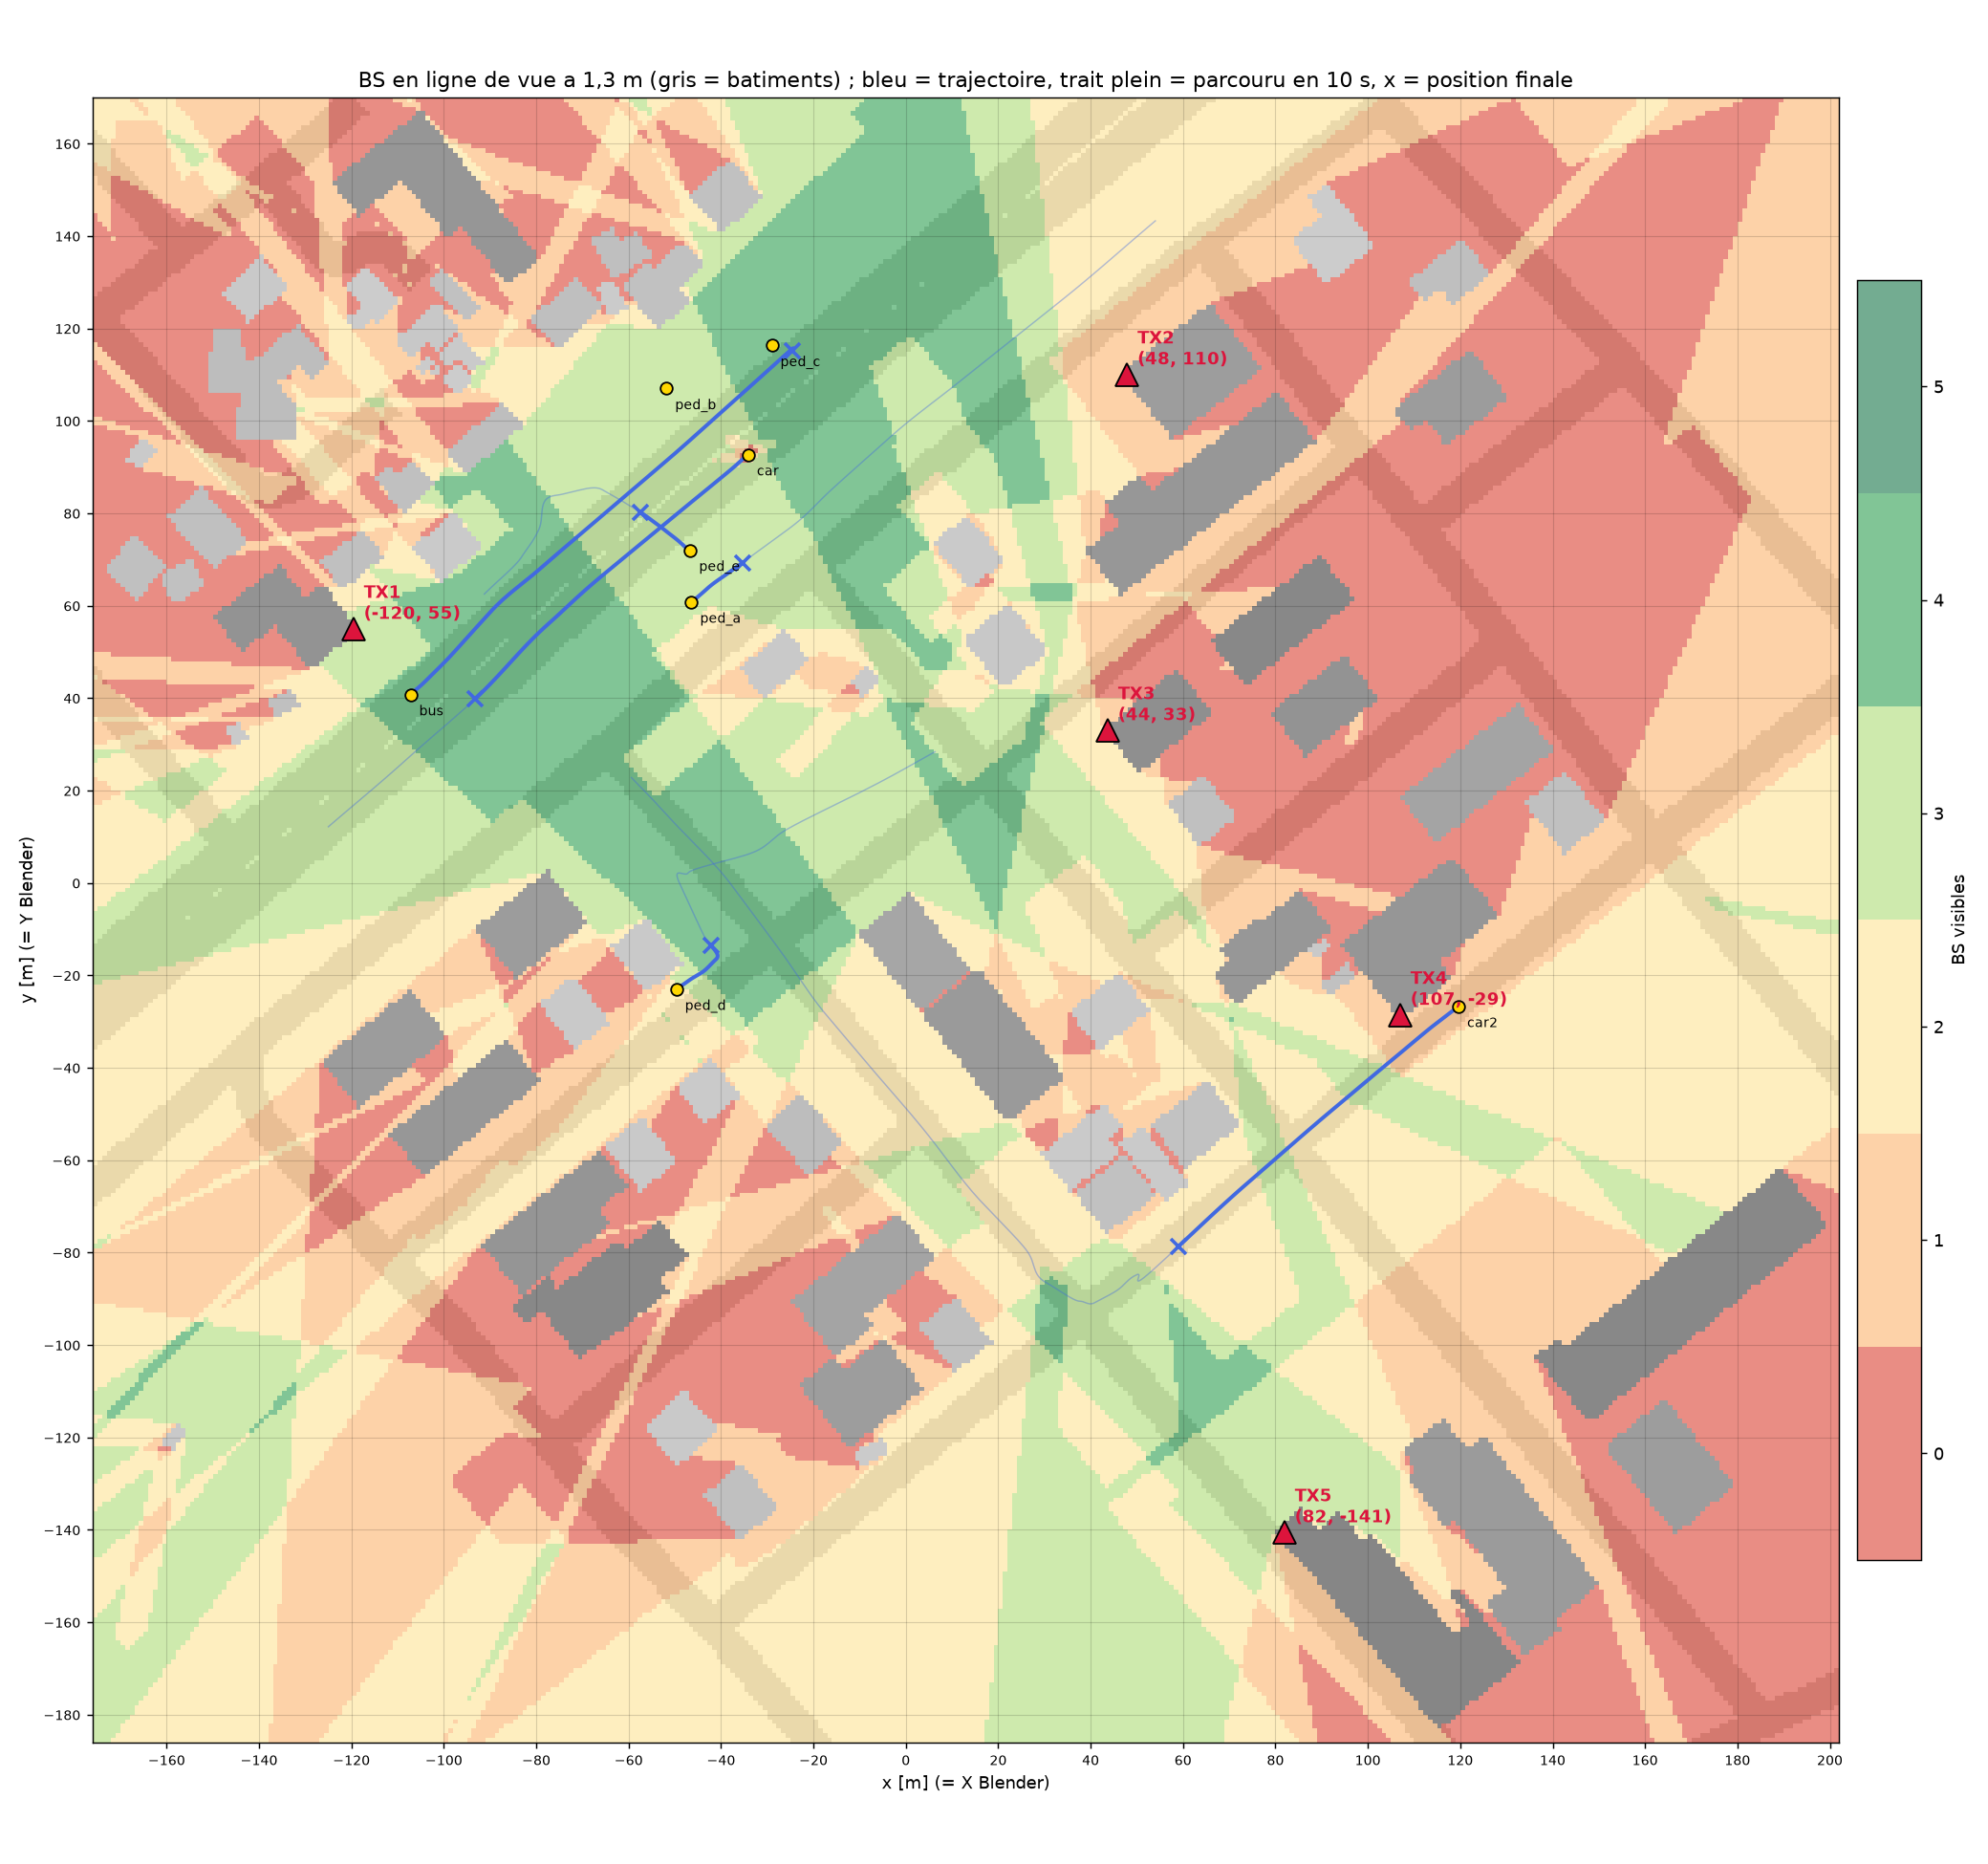

In [2]:
mr = S2["monde_reel"]["acteurs"]
df = pd.DataFrame({a: {"classe": v["classe"], "vitesse [m/s]": v["vitesse_m_s"],
                       "longueur courbe [m]": v["trajectoire_m"],
                       "parcouru en 10 s [m]": min(v["trajectoire_m"], v["vitesse_m_s"] * T * S2["frame_s"]),
                       "UE": "oui" if v["ue"] else "non"} for a, v in mr.items()}).T
display(df)
display(Image(filename=str(E1 / "carte_visibilite_BS.png"), width=900))

*Carte : nombre de BS en ligne de vue à 1,3 m du sol (calcul sur la scène de base). En bleu, les
trajectoires ; trait plein = partie parcourue en 10 s ; × = position finale.*

## 2. Étape 2 — canal réel FR2 et codebook (M6)

Pour chaque frame et chaque couple BS–UE, Sionna RT calcule le canal sur la scène **réelle**
(mobilier inconnu du jumeau, matériaux perturbés de ±20 %, diffusion diffuse, diffraction, 4 rebonds) :

- 28 GHz, 400 MHz, 16 sous-porteuses ; réseau UPA 16×16 (motif 3GPP TR 38.901) à la BS, antenne isotrope à l'UE ;
- un panneau par BS, orienté vers le barycentre des positions des UE (planification du site) ;
- codebook DFT 2D de 256 faisceaux : $G_b = \frac{1}{F}\sum_f |\mathbf{w}_b^T \mathbf{h}_t(f)|^2$ ;
- SNR $= P_{tx} + 10\log_{10} G_b - N$, avec $P_{tx} = 30$ dBm et $N = -81$ dBm (400 MHz, NF 7 dB).

Le **meilleur faisceau** (balayage exhaustif) et la **meilleure BS** servent de vérité terrain à toutes
les méthodes des étapes suivantes.

In [3]:
p = S2["bande"] | S2["bs"] | {"codebook": f'{S2["codebook"]["type"]}, {S2["codebook"]["N"]} faisceaux',
                              "temps de calcul": f'{S2["temps_calcul_s"]:.0f} s'}
display(pd.Series(p, name="paramètre").to_frame())

,paramètre
frequence_ghz,28.0
largeur_mhz,400.0
sous_porteuses,16
reseau,"UPA 16x16 tr38901, pol. V"
p_tx_dbm,30.0
bruit_dbm,-81.0
cible_secteur,"[-27.4, 51.7, 1.5]"
codebook,"DFT 2D, 256 faisceaux"
temps de calcul,381 s


### 2.1 Vérifications

1. **Convention de phase du codebook.** En ligne de vue, le faisceau qui pointe géométriquement vers
   l'UE doit être (presque) le meilleur. Avec le mauvais signe de phase, il perdrait 15 à 25 dB.
2. **Stabilité de la diffusion diffuse.** La diffusion diffuse est tirée au hasard par Sionna : on
   recalcule quelques frames avec une autre graine et on compare le meilleur faisceau.
3. **Trajets comptés plusieurs fois.** Sionna RT (1.2.2) reconnaît une réflexion déjà trouvée par un
   hachage du plan réfléchissant, dont l'offset est arrondi à 1 mm. À une centaine de mètres de la BS,
   l'erreur d'intersection en simple précision est du même ordre : des rayons qui frappent le même
   triangle tombent de part et d'autre d'un pas d'arrondi et la même réflexion est stockée plusieurs
   fois (jusqu'à 8 copies sur le flanc du bus). Une chaîne de réflexions/diffractions est entièrement
   définie par la suite (type, objet, triangle) de ses interactions : on n'en garde qu'une
   (`dt_common.dedupe_paths`). Les trajets diffus, échantillons distincts par construction, ne sont pas touchés.

Liens LOS ou le faisceau geometrique est a moins de 1 dB du meilleur : 97.8%
Autre graine (8 frames) : meme faisceau optimal dans 96% des cas, ecart de gain optimal median 0.07 dB, p90 2.20 dB
Trajets dupliques supprimes : 380 sur 45 frames (au plus 12.4% de la puissance d'une frame)
Effet sur le SNR du meilleur faisceau : liens surestimes de plus de 1 dB 1.0%, de plus de 3 dB 0.9%, ecart max 16.2 dB


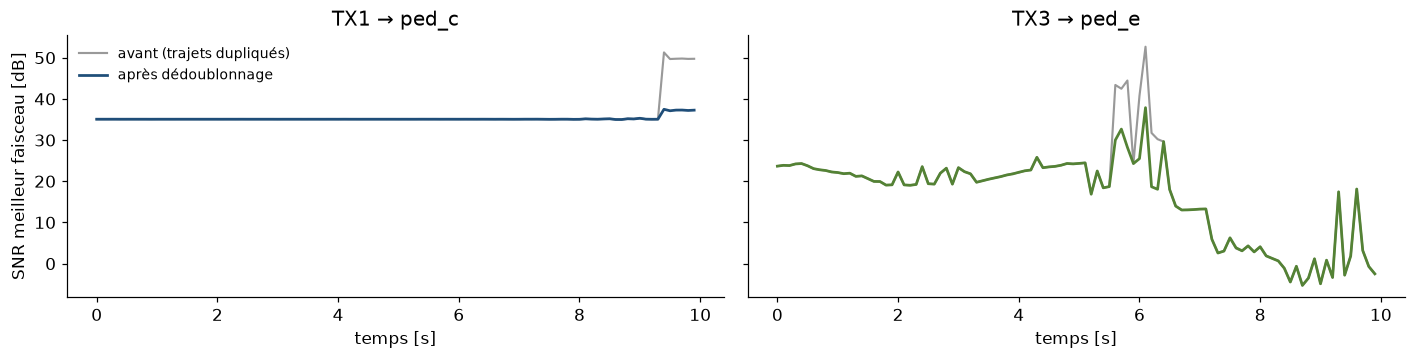

In [4]:
v = S2["validation"]
print(f"Liens LOS ou le faisceau geometrique est a moins de 1 dB du meilleur : {v['codebook_LOS_faisceau_geometrique_a_1dB_du_meilleur']:.1%}")
d = v["variabilite_diffuse"]
print(f"Autre graine ({len(d['frames'])} frames) : meme faisceau optimal dans {d['meme_faisceau_optimal']:.0%} des cas, "
      f"ecart de gain optimal median {d['ecart_gain_optimal_median_db']:.2f} dB, p90 {d['ecart_gain_optimal_p90_db']:.2f} dB")
dd = S2["trace"].get("trajets_dupliques_supprimes")
if dd:
    print(f"Trajets dupliques supprimes : {dd['total']} sur {dd['frames_concernees']} frames "
          f"(au plus {dd['part_puissance_max_frame']:.1%} de la puissance d'une frame)")
V0 = ROOT / "etape2_v0_avec_doublons" / "canal_reel_fr2.npz"
if V0.exists():
    snr0 = np.load(V0, allow_pickle=True)["snr_best_db"]
    diff = snr0 - SNR
    print(f"Effet sur le SNR du meilleur faisceau : liens surestimes de plus de 1 dB {np.mean(diff > 1):.1%}, "
          f"de plus de 3 dB {np.mean(diff > 3):.1%}, ecart max {diff.max():.1f} dB")
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
    for ax, (a, n) in zip(axes, (("ped_c", "TX1"), ("ped_e", "TX3"))):
        j, i = UES.index(a), BS.index(n)
        ax.plot(t_s, snr0[:, i, j], color="0.6", lw=1.4, label="avant (trajets dupliqués)")
        ax.plot(t_s, SNR[:, i, j], color=BS_COL[n], lw=1.8, label="après dédoublonnage")
        ax.set(title=f"{n} → {a}", xlabel="temps [s]")
    axes[0].set_ylabel("SNR meilleur faisceau [dB]")
    axes[0].legend(frameon=False, fontsize=9)
    fig.tight_layout()
    plt.show()

### 2.2 SNR du meilleur faisceau, par UE et par BS

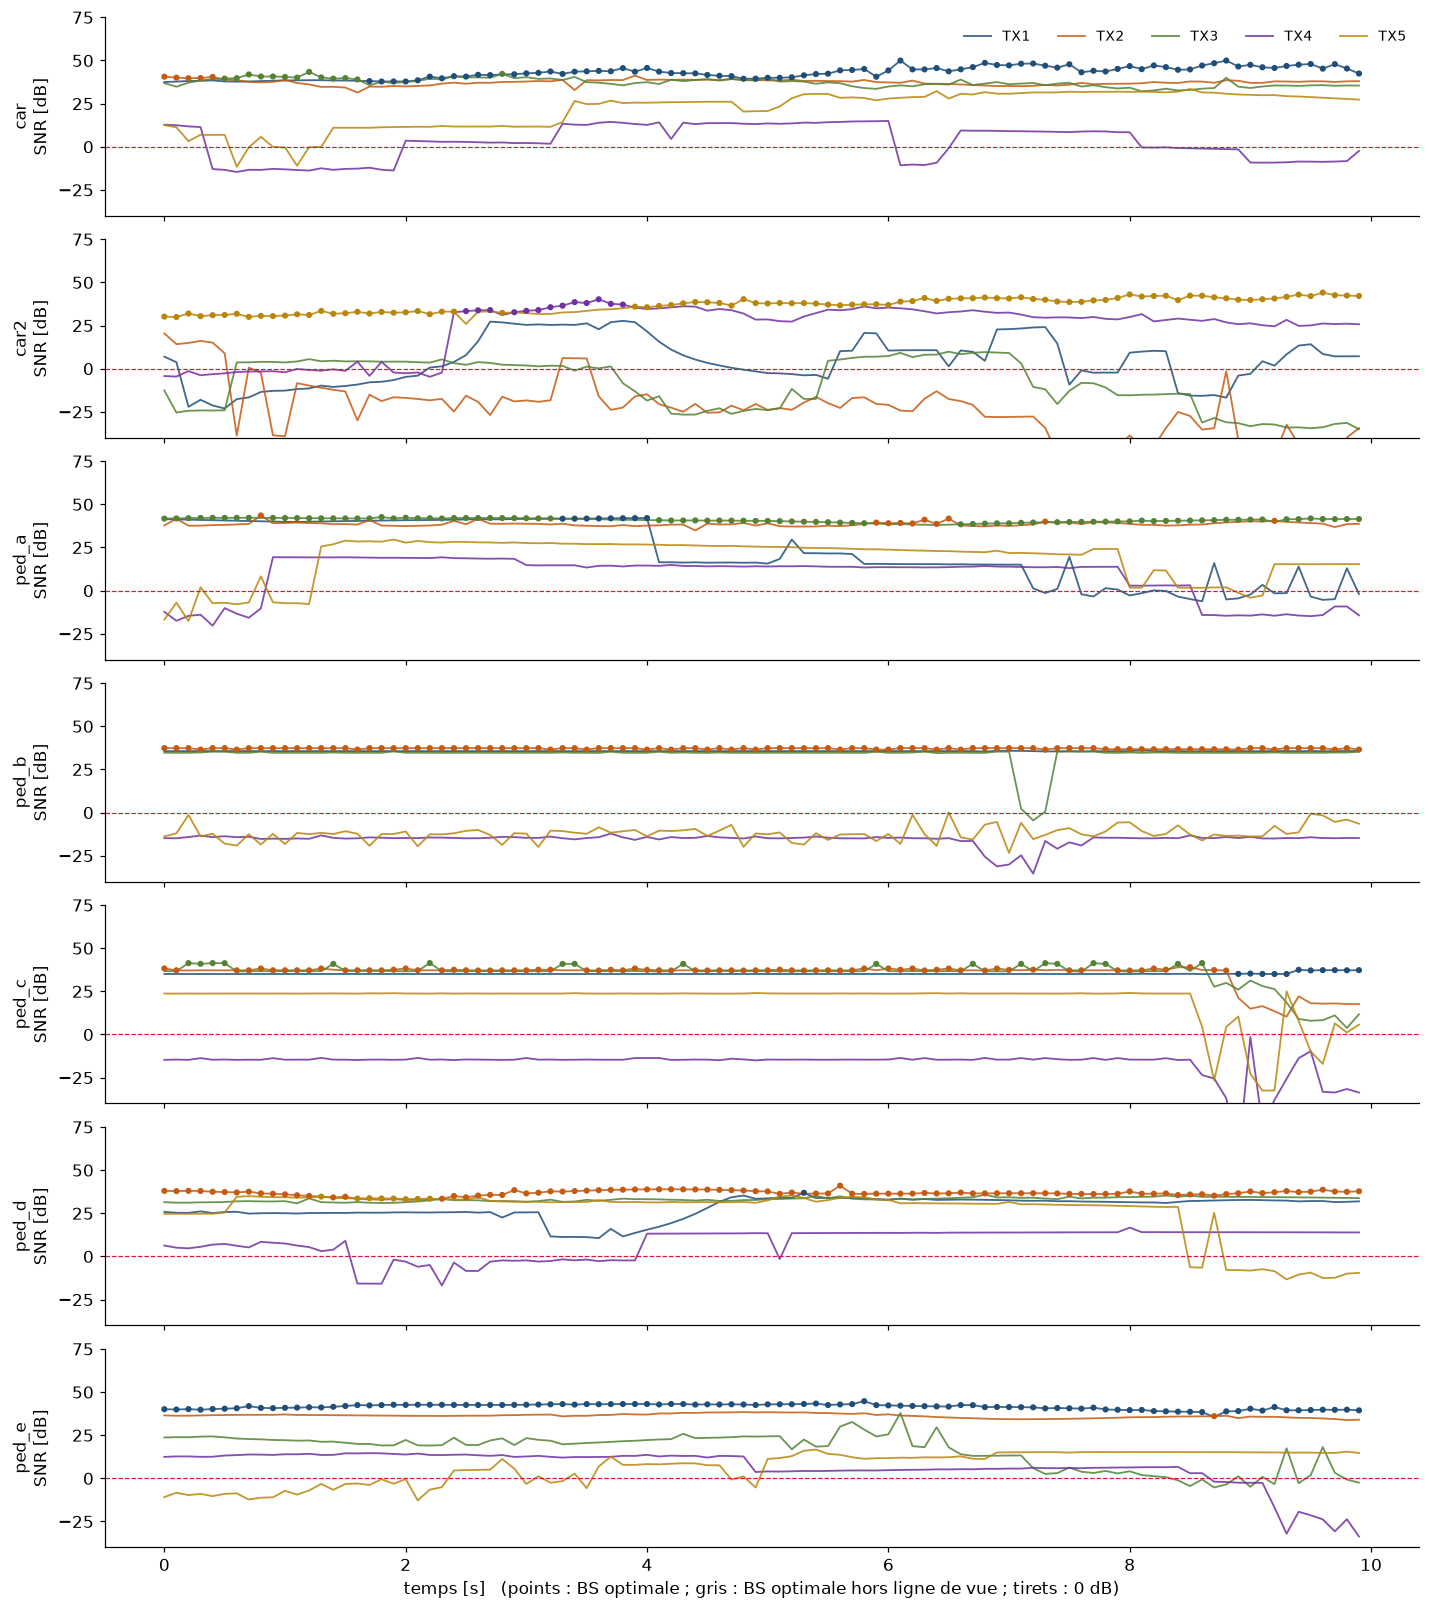

In [5]:
fig, axes = plt.subplots(U, 1, figsize=(13, 2.1 * U), sharex=True)
for j, a in enumerate(UES):
    ax = axes[j]
    for i, n in enumerate(BS):
        ax.plot(t_s, SNR[:, i, j], color=BS_COL[n], lw=1.2, alpha=0.85, label=n)
    ax.scatter(t_s, SNR_ORACLE[:, j], c=[BS_COL[BS[b]] for b in BEST_BS[:, j]], s=9, zorder=3)
    ax.fill_between(t_s, -40, 80, where=~SERVED_LOS[:, j], color="0.88", step="mid", zorder=0)
    ax.axhline(0, color="crimson", lw=0.8, ls="--")
    ax.set_ylim(-40, 75)
    ax.set_ylabel(f"{a}\nSNR [dB]")
axes[0].legend(ncol=NB, frameon=False, loc="upper right", fontsize=9)
axes[-1].set_xlabel("temps [s]   (points : BS optimale ; gris : BS optimale hors ligne de vue ; tirets : 0 dB)")
fig.tight_layout()
plt.show()

### 2.3 BS optimale et ligne de vue au cours du temps

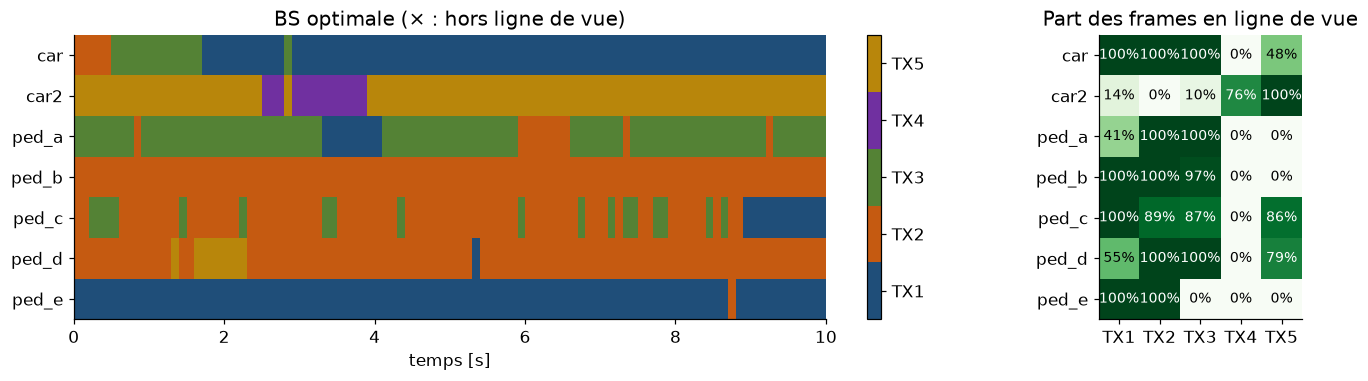

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
im = axes[0].imshow(BEST_BS.T, aspect="auto", cmap=ListedColormap([BS_COL[n] for n in BS]),
                    vmin=-0.5, vmax=NB - 0.5, interpolation="nearest", extent=[0, T * S2["frame_s"], U, 0])
yy, xx = np.nonzero(~SERVED_LOS.T)
axes[0].scatter(xx * S2["frame_s"] + 0.05, yy + 0.5, marker="x", s=8, color="w", lw=0.7)
axes[0].set_yticks(np.arange(U) + 0.5, UES)
axes[0].set(xlabel="temps [s]", title="BS optimale (× : hors ligne de vue)")
cb = fig.colorbar(im, ax=axes[0], ticks=range(NB), fraction=0.03)
cb.ax.set_yticklabels(BS)
share = np.array([[LOS[:, i, j].mean() for i in range(NB)] for j in range(U)])
im2 = axes[1].imshow(share, cmap="Greens", vmin=0, vmax=1)
for j in range(U):
    for i in range(NB):
        axes[1].text(i, j, f"{share[j, i]:.0%}", ha="center", va="center", fontsize=9,
                     color="w" if share[j, i] > 0.6 else "k")
axes[1].set_xticks(range(NB), BS)
axes[1].set_yticks(range(U), UES)
axes[1].set_title("Part des frames en ligne de vue")
fig.tight_layout()
plt.show()

### 2.4 Bilan par UE

In [7]:
ev = S2["evenements_par_ue"]
tab = pd.DataFrame({a: {"BS optimale (frames)": ", ".join(f"{n}:{k}" for n, k in e["bs_optimales"].items() if k),
                        "changements de BS": e["changements_bs_optimale"],
                        "changements de faisceau": e["changements_faisceau_optimal"],
                        "BS optimale en LOS": f'{e["part_frames_bs_optimale_en_LOS"]:.0%}',
                        "SNR médian [dB]": e["snr_oracle_median_db"],
                        "SNR min [dB]": e["snr_oracle_min_db"],
                        "coupure (< 0 dB)": f'{e["part_coupure"]:.0%}',
                        "pertes de LOS de la BS servante": len(e["pertes_LOS_bs_servante"])}
                    for a, e in ev.items()}).T
display(tab)
rows = [{"UE": a, "t [s]": x["frame"] * S2["frame_s"], "BS": x["bs"], "obstacle": x["obstacle"]}
        for a, e in ev.items() for x in e["pertes_LOS_bs_servante"]]
print("Pertes de ligne de vue de la BS servante :")
display(pd.DataFrame(rows) if rows else "aucune")
print("Obstacles des liens hors ligne de vue (toutes BS, toutes frames) :", S2["obstacles_liens_NLOS"])

,BS optimale (frames),changements de BS,changements de faisceau,BS optimale en LOS,SNR médian [dB],SNR min [dB],coupure (< 0 dB),pertes de LOS de la BS servante
car,"TX1:82, TX2:5, TX3:13",4,9,100%,43.41,37.77,0%,0
car2,"TX4:13, TX5:87",4,5,100%,37.87,29.92,0%,0
ped_a,"TX1:8, TX2:10, TX3:82",10,0,100%,41.17,38.41,0%,0
ped_b,TX2:100,0,0,100%,37.33,36.47,0%,0
ped_c,"TX1:11, TX2:71, TX3:18",25,0,100%,37.2,35.04,0%,0
ped_d,"TX1:1, TX2:91, TX5:8",6,0,100%,36.58,33.19,0%,0
ped_e,"TX1:99, TX2:1",2,1,100%,41.89,36.02,0%,0


Pertes de ligne de vue de la BS servante :


'aucune'

Obstacles des liens hors ligne de vue (toutes BS, toutes frames) : {'batiment/sol': 1303, 'acteur': 215}


**BS optimale « oracle » et quasi-égalités.** Quand deux BS donnent presque le même SNR, la BS
optimale change d'une frame à l'autre au gré de petites fluctuations (diffusion diffuse tirée à
chaque frame), sans que cela corresponde à un vrai événement. On compte ces quasi-égalités, et les
changements de BS que ferait une règle avec **hystérésis** (on ne change que si la nouvelle BS est
meilleure de 3 dB) : ce sont ces changements-là qu'un prédicteur devra anticiper.

In [8]:
srt = np.sort(SNR, axis=1)
gap12 = srt[:, -1] - srt[:, -2]                           # ecart entre la meilleure et la 2e BS [T, UE]


def hysteresis(j, h_db=3.0):
    cur, n_sw, loss = BEST_BS[0, j], 0, []
    for t in range(T):
        if SNR[t, BEST_BS[t, j], j] > SNR[t, cur, j] + h_db:
            cur, n_sw = BEST_BS[t, j], n_sw + 1
        loss.append(SNR_ORACLE[t, j] - SNR[t, cur, j])
    return n_sw, np.max(loss)


hy = {a: hysteresis(j) for j, a in enumerate(UES)}
display(pd.DataFrame({a: {"changements oracle": int(np.sum(BEST_BS[1:, j] != BEST_BS[:-1, j])),
                          "frames avec 2e BS à < 1 dB": f"{np.mean(gap12[:, j] < 1):.0%}",
                          "changements avec hystérésis 3 dB": hy[a][0],
                          "perte max due à l'hystérésis [dB]": round(hy[a][1], 1)}
                      for j, a in enumerate(UES)}).T)

,changements oracle,frames avec 2e BS à < 1 dB,changements avec hystérésis 3 dB,perte max due à l'hystérésis [dB]
car,4,13%,2,2.4
car2,4,6%,2,2.7
ped_a,10,35%,2,2.9
ped_b,0,20%,0,0.0
ped_c,25,57%,3,2.2
ped_d,6,18%,0,0.8
ped_e,2,1%,0,0.4


### 2.5 Zoom : le bus arrive à l'arrêt de ped_c

Le bus (11 m × 3 m × 3,1 m, métal) arrive à l'arrêt et frôle ped_c (1 m) vers t = 9,3 s. Pour chaque
BS : SNR du meilleur faisceau de ped_c et état de la ligne de vue, avec la distance bus–ped_c.
Le bus coupe successivement TX5, TX3 puis TX2 (la BS qui servait ped_c 71 % du temps) : leur SNR
chute de 20 à 25 dB. Seule TX1, de l'autre côté, reste en ligne de vue ; la BS optimale doit passer
à TX1. C'est le type d'événement que le jumeau doit permettre d'**anticiper** (le bus est visible
plusieurs secondes avant).

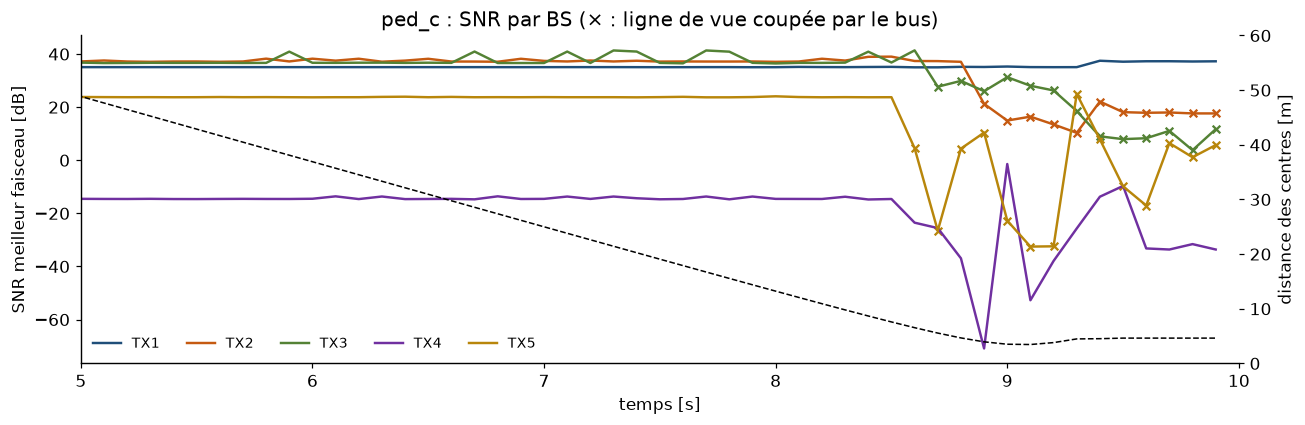

SNR a t = 8,0 s : {np.str_('TX1'): np.float64(35.0), np.str_('TX2'): np.float64(37.1), np.str_('TX3'): np.float64(36.4), np.str_('TX4'): np.float64(-14.6), np.str_('TX5'): np.float64(24.1)}
SNR a t = 9,9 s : {np.str_('TX1'): np.float64(37.3), np.str_('TX2'): np.float64(17.6), np.str_('TX3'): np.float64(11.7), np.str_('TX4'): np.float64(-33.6), np.str_('TX5'): np.float64(5.7)}


In [9]:
j = UES.index("ped_c")
st = R2["actor_state"]                        # [acteur, T, (x, y, z, vx, vy, cap)]
d_bus = np.linalg.norm(st[ACT.index("bus"), :, :2] - st[ACT.index("ped_c"), :, :2], axis=1)
fig, ax = plt.subplots(figsize=(12, 4))
for i, n in enumerate(BS):
    ax.plot(t_s, SNR[:, i, j], color=BS_COL[n], lw=1.6, label=n)
    blk = np.array(["bus" in b for b in BLOCK[:, i, j]])
    ax.scatter(t_s[blk], SNR[blk, i, j], color=BS_COL[n], marker="x", s=25)
ax2 = ax.twinx()
ax2.plot(t_s, d_bus, "k--", lw=1, label="distance bus–ped_c")
ax2.set_ylabel("distance des centres [m]")
ax2.set_ylim(0, 60)
ax.set(xlabel="temps [s]", ylabel="SNR meilleur faisceau [dB]", xlim=(5, 10),
       title="ped_c : SNR par BS (× : ligne de vue coupée par le bus)")
ax.legend(ncol=NB, frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()
a, b = SNR[80, :, j], SNR[-1, :, j]
print("SNR a t = 8,0 s :", dict(zip(BS, a.round(1))))
print("SNR a t = 9,9 s :", dict(zip(BS, b.round(1))))

### 2.6 Le meilleur faisceau dans le codebook

Gain des 256 faisceaux d'une BS (grille $u, v$ du panneau : $u$ horizontal, $v$ vertical) pour un lien
en ligne de vue et un lien hors ligne de vue, puis trajectoire du meilleur faisceau de la BS servante
au cours de la séquence pour chaque UE mobile.

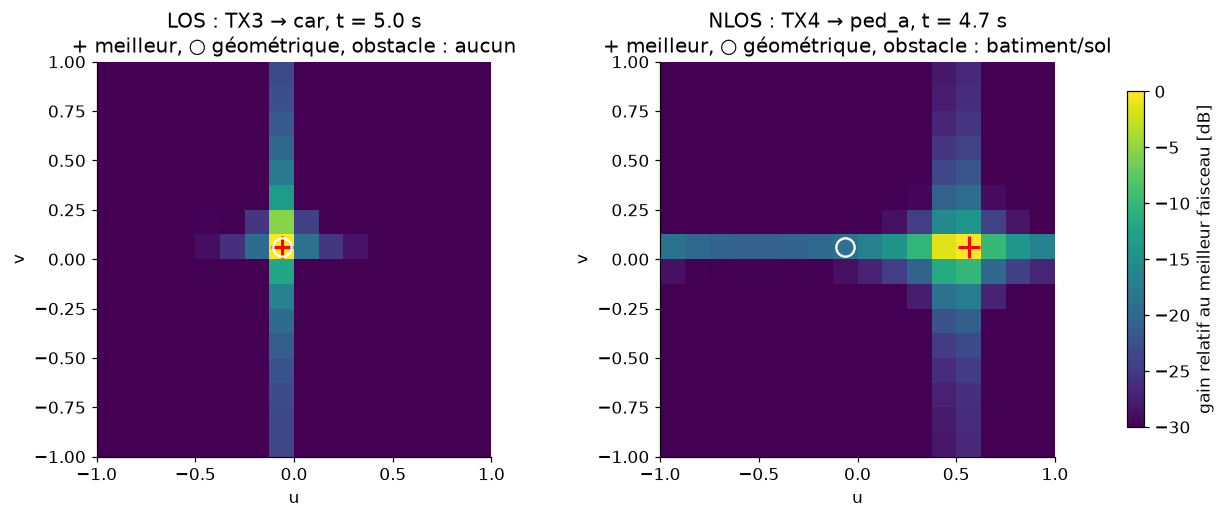

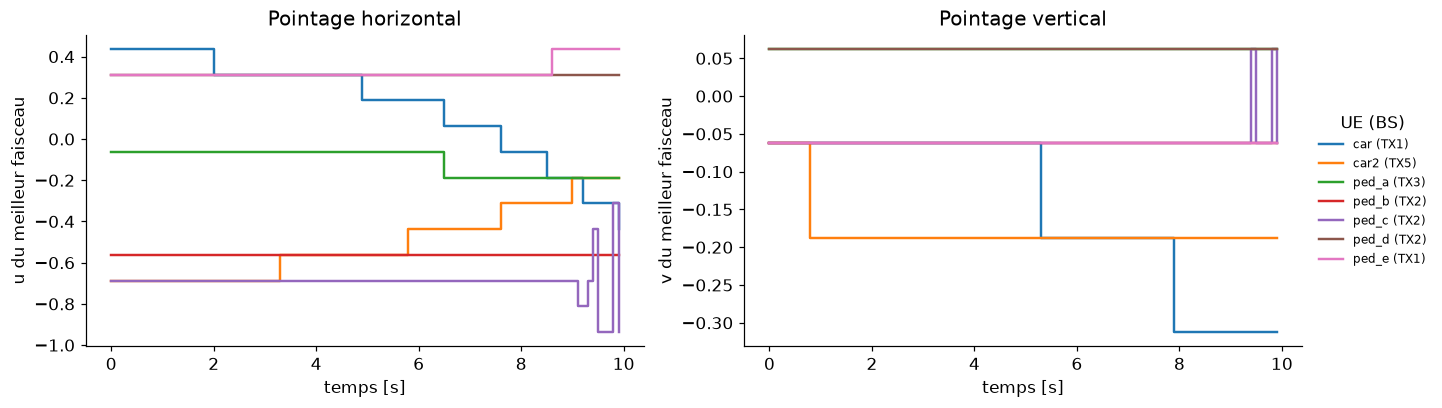

In [10]:
def gain_map(t, i, j):
    g = 10 * np.log10(G[t, i, j] / G[t, i, j].max() + 1e-12)
    return g.reshape(16, 16).T                # lignes = v, colonnes = u

los_ex = np.argwhere(LOS)
nlos_ex = np.argwhere(~LOS & (SNR > 10))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), layout="constrained")
for ax, (t, i, j), lab in ((axes[0], los_ex[len(los_ex) // 2], "LOS"), (axes[1], nlos_ex[len(nlos_ex) // 2], "NLOS")):
    im = ax.imshow(gain_map(t, i, j), origin="lower", extent=[-1, 1, -1, 1], vmin=-30, vmax=0, cmap="viridis")
    b = BEST_BEAM[t, i, j]
    ax.plot(*UV[b], "r+", ms=14, mew=2)
    g0 = R2["geo_beam"][t, i, j]
    if g0 >= 0:
        ax.plot(*UV[g0], "wo", mfc="none", ms=12, mew=1.5)
    ax.set(xlabel="u", ylabel="v", title=f"{lab} : {BS[i]} → {UES[j]}, t = {t * S2['frame_s']:.1f} s\n"
                                         f"+ meilleur, ○ géométrique, obstacle : {BLOCK[t, i, j]}")
fig.colorbar(im, ax=axes, label="gain relatif au meilleur faisceau [dB]", shrink=0.85)
plt.show()

# Meilleur faisceau de la BS la plus souvent optimale de chaque UE : indices (u, v) au cours du temps
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharex=True, layout="constrained")
for j, a in enumerate(UES):
    i = np.bincount(BEST_BS[:, j], minlength=NB).argmax()
    uv = UV[BEST_BEAM[:, i, j]]
    axes[0].step(t_s, uv[:, 0], where="post", lw=1.6, label=f"{a} ({BS[i]})")
    axes[1].step(t_s, uv[:, 1], where="post", lw=1.6)
axes[0].set(xlabel="temps [s]", ylabel="u du meilleur faisceau", title="Pointage horizontal")
axes[1].set(xlabel="temps [s]", ylabel="v du meilleur faisceau", title="Pointage vertical")
axes[1].legend(*axes[0].get_legend_handles_labels(), fontsize=8, frameon=False, loc="center left",
               bbox_to_anchor=(1.01, 0.5), title="UE (BS)")
plt.show()

### 2.7 Aperçu de la référence J0 : pointer vers la vraie position de l'UE

Le faisceau géométrique est celui dont la direction est la plus proche de la direction BS → UE
(position vraie). Sa perte par rapport au meilleur faisceau mesure ce que l'on perd **sans aucun
modèle de propagation**, même en connaissant parfaitement la position.

C:\Users\AdminFix\AppData\Local\Temp\ipykernel_22588\3289332982.py:4: RuntimeWarning: divide by zero encountered in log10
  loss = 10 * np.log10(g_best / np.maximum(g_geo, 1e-30))


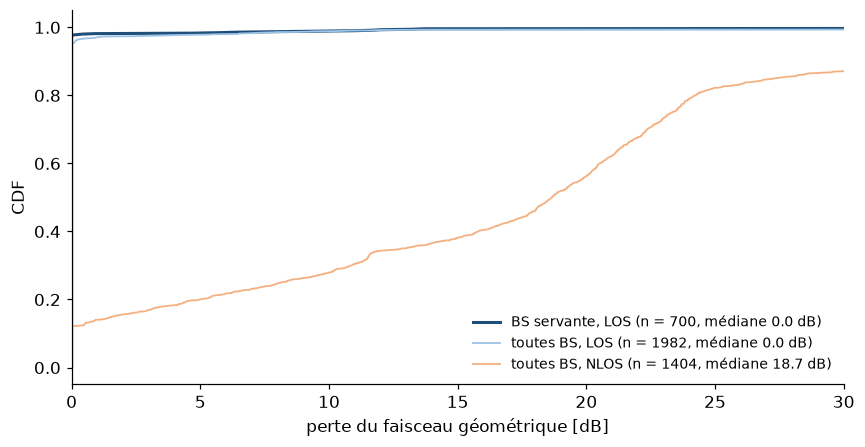

In [11]:
geo = R2["geo_beam"]
g_best = G.max(-1)
g_geo = np.where(geo >= 0, np.take_along_axis(G, np.clip(geo, 0, None)[..., None], -1)[..., 0], 0)
loss = 10 * np.log10(g_best / np.maximum(g_geo, 1e-30))
srv = (np.arange(NB)[None, :, None] == BEST_BS[:, None, :])          # lien vers la BS servante
fig, ax = plt.subplots(figsize=(8, 4.2))
for m, lab, c in ((LOS & srv, "BS servante, LOS", "#1f4e79"), (~LOS & srv, "BS servante, NLOS", "#c55a11"),
                  (LOS, "toutes BS, LOS", "#9dc3e6"), (~LOS & (geo >= 0), "toutes BS, NLOS", "#f4b183")):
    x = np.sort(np.minimum(loss[m], 40))
    if len(x):
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=c, lw=2 if "servante" in lab else 1.2,
                label=f"{lab} (n = {len(x)}, médiane {np.median(x):.1f} dB)")
ax.set(xlim=(0, 30), xlabel="perte du faisceau géométrique [dB]", ylabel="CDF")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 3. Étape 1 — le jumeau de la phase 5, frame par frame (M1)

Même chaîne que la phase 5 (radar FR1 et FR2, vision YOLOv8n fine-tunée, fusion, filtre « au moins deux
points de vue »), appliquée aux 100 frames, avec trois changements imposés par l'usage en ligne :

- **caméras fixes**, planifiées une fois pour couvrir les rues (au plus 4 par BS, 2 par poteau) ;
- **confirmation causale** : un objet est retenu s'il existe déjà à la frame précédente (la phase 5
  utilisait aussi la frame suivante, impossible en temps réel) ; la frame 0 est donc vide ;
- autant d'acteurs que la scène en contient.

Quatre configurations, chacune sur 5 tirages du bruit de mesure :

| Config. | Bandes | Objets créés par la vision |
|---|---|---|
| C1 | FR1 | non |
| C2 | FR2 | non |
| C3 | FR1 + FR2 | non |
| C4 | FR1 + FR2 | oui |

In [12]:
if not STEP1:
    print("Etape 1 pas encore disponible.")
else:
    res = S1["resultats_couche_dynamique"]
    rows = []
    for cfg, r in res.items():
        for a, m in r["acteurs"].items():
            rows.append({"config": cfg.split("_")[0], "acteur": a, "détecté": m["detecte"][0],
                         "bien classé": m["bien_classe"][0], "erreur [m]": m["erreur_moyenne_m"][0]})
    D1 = pd.DataFrame(rows)
    display(D1.pivot(index="acteur", columns="config", values="détecté").style.format("{:.0%}")
            .set_caption("Part des frames où l'acteur est dans le jumeau (< 3 m)"))
    display(D1.pivot(index="acteur", columns="config", values="bien classé").style.format("{:.0%}")
            .set_caption("Part des frames où il est détecté ET bien classé"))
    display(D1.pivot(index="acteur", columns="config", values="erreur [m]").style.format("{:.2f}")
            .set_caption("Erreur de position moyenne quand il est détecté [m]"))
    display(pd.DataFrame({c.split("_")[0]: {"faux objets / frame": f"{r['faux_objets_par_frame'][0]:.2f} ± {r['faux_objets_par_frame'][1]:.2f}"}
                          for c, r in res.items()}))
    print(f"{len(S1['cameras'])} cameras fixes ; rendu {S1['rendu_echantillons']} echantillons ; "
          f"calcul {S1['temps_calcul_s'] / 60:.0f} min")

config,C1,C2,C3,C4
acteur,,,,
bus,88%,95%,94%,94%
car,90%,98%,91%,91%
car2,49%,74%,75%,75%
ped_a,0%,63%,63%,100%
ped_b,0%,0%,0%,81%
ped_c,0%,0%,0%,0%
ped_d,0%,49%,49%,54%
ped_e,0%,53%,49%,82%


config,C1,C2,C3,C4
acteur,,,,
bus,0%,0%,0%,0%
car,90%,98%,91%,91%
car2,49%,74%,75%,75%
ped_a,0%,61%,61%,100%
ped_b,0%,0%,0%,81%
ped_c,0%,0%,0%,0%
ped_d,0%,4%,4%,10%
ped_e,0%,46%,43%,75%


config,C1,C2,C3,C4
acteur,,,,
bus,1.49,1.11,1.18,1.18
car,0.68,0.39,0.39,0.39
car2,0.89,0.76,0.82,0.82
ped_a,nan,0.48,0.48,0.21
ped_b,2.09,nan,nan,0.20
ped_c,nan,nan,nan,nan
ped_d,nan,0.65,0.65,0.63
ped_e,nan,0.52,0.53,0.41


,C1,C2,C3,C4
faux objets / frame,0.07 ± 0.01,0.13 ± 0.03,0.14 ± 0.02,0.14 ± 0.01


22 cameras fixes ; rendu 256 echantillons ; calcul 66 min


### 3.1 Détection de chaque acteur au cours du temps (tirage 0)

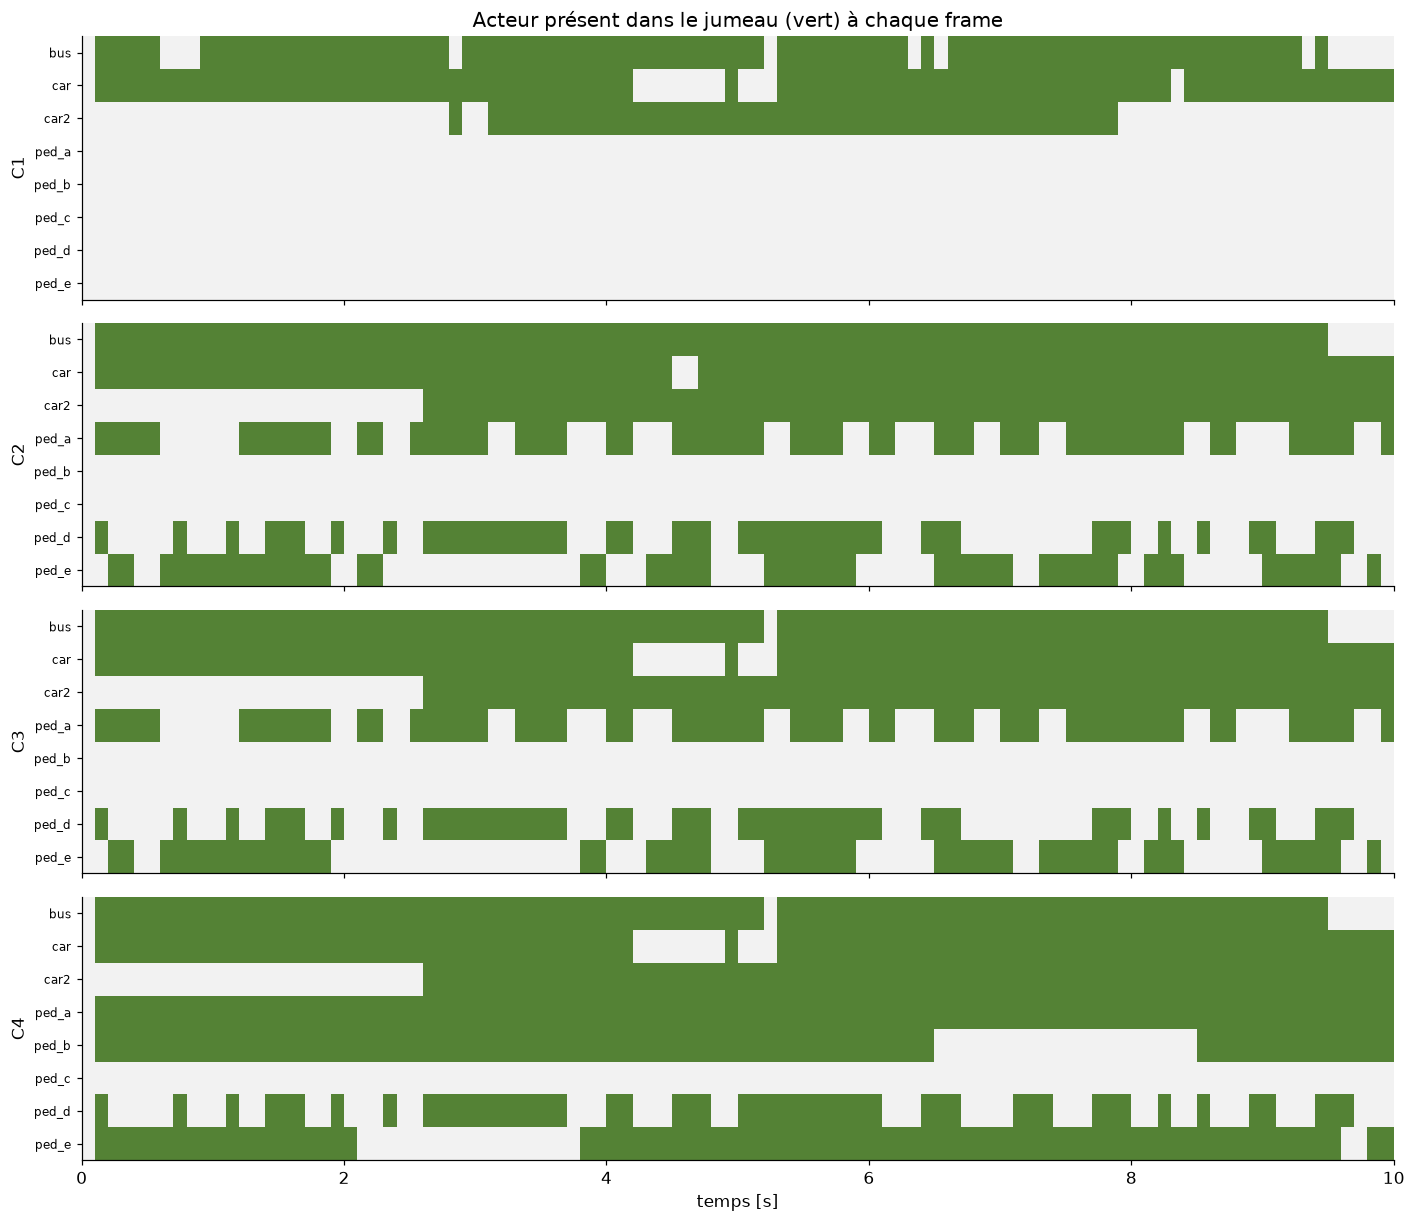

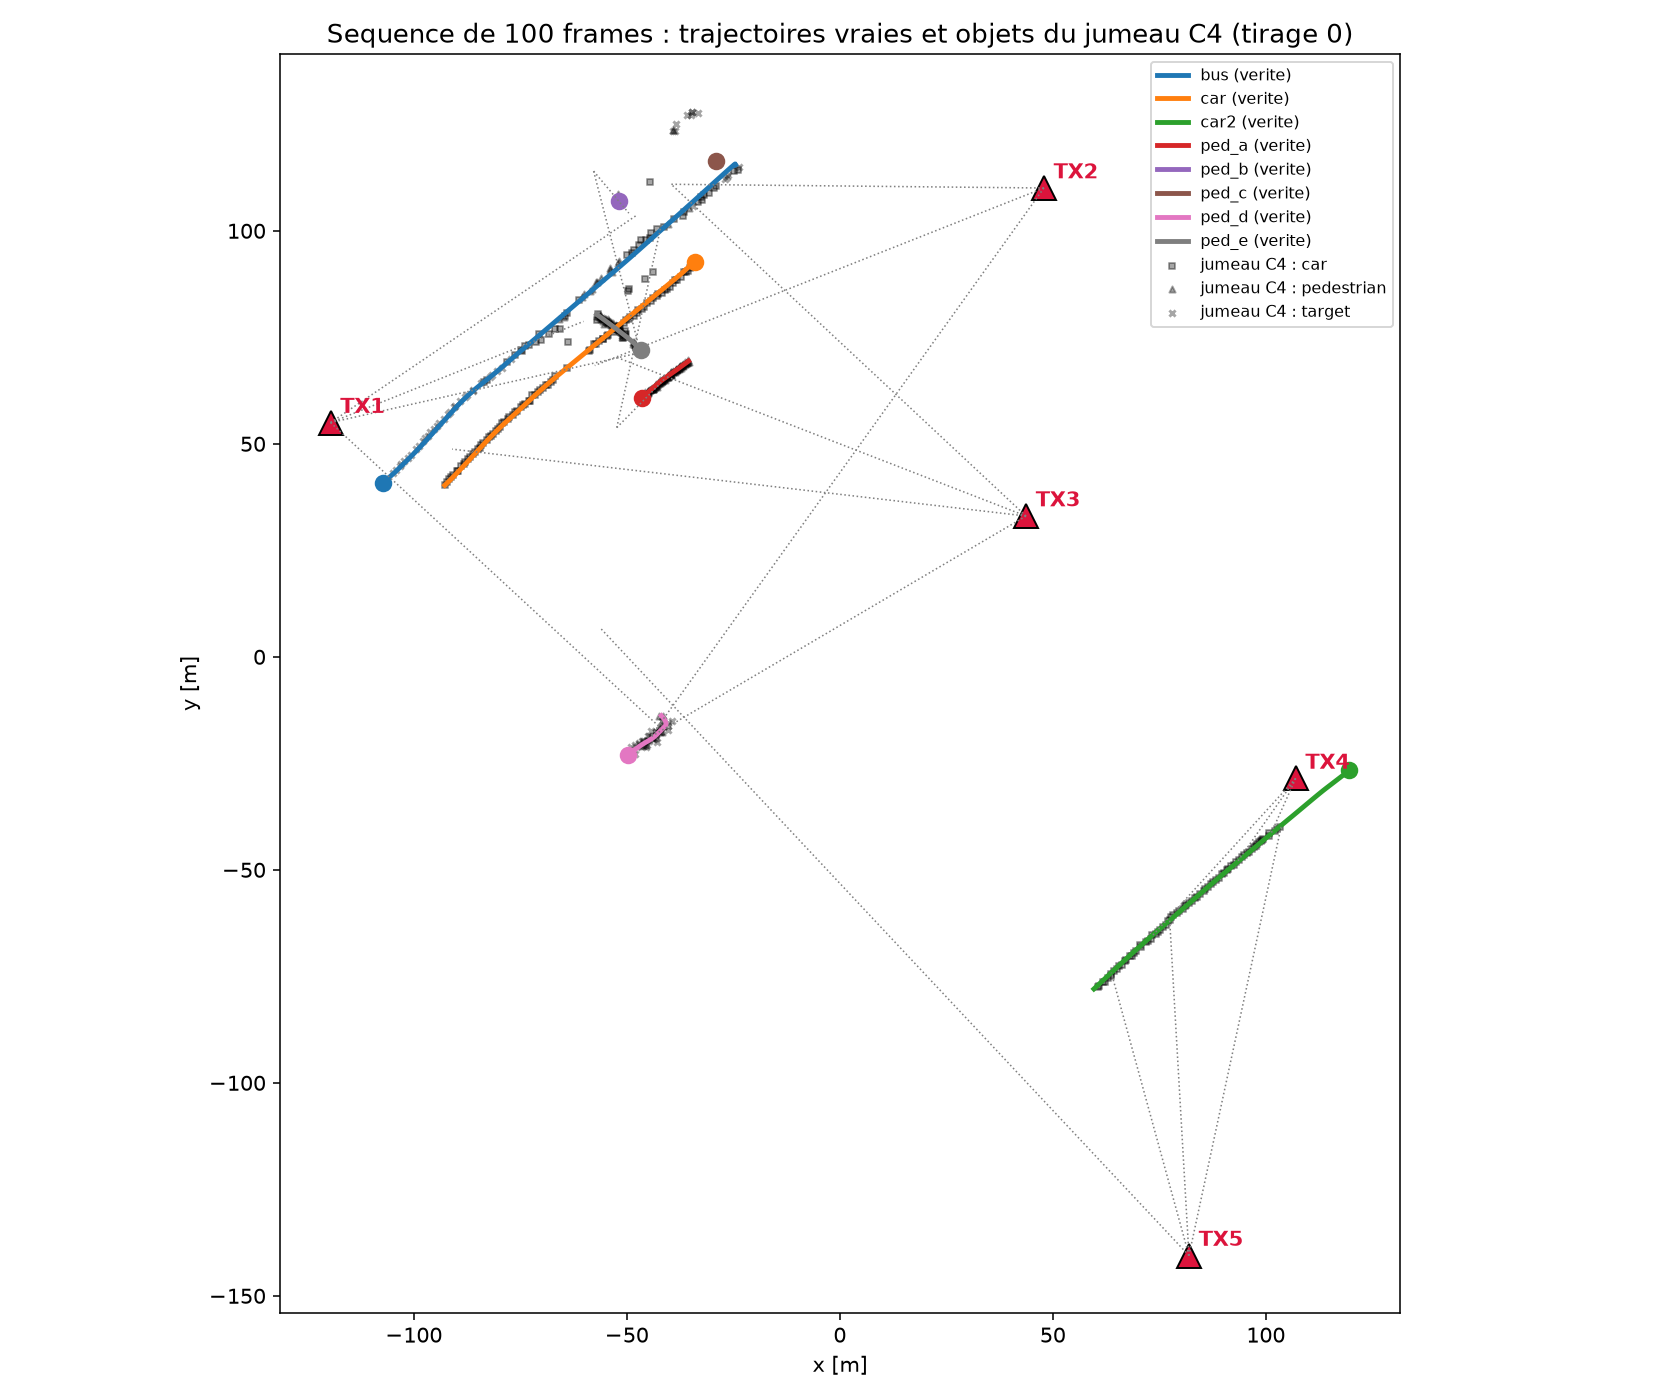

In [13]:
if STEP1:
    names = list(GT1["actor_names"]); gxy = GT1["actor_xy"]           # [T, acteur, 2]
    cfgs = J1["configs"]
    fig, axes = plt.subplots(len(cfgs), 1, figsize=(13, 1.0 + 0.32 * len(names) * len(cfgs)), sharex=True)
    ERR1 = {}
    for ax, cfg in zip(axes, cfgs):
        tw = J1["jumeau"][cfg][0]
        M = np.full((len(names), T), np.nan)
        for t in range(T):
            objs = np.array([o["xy"] for o in tw[t]]).reshape(-1, 2)
            for k in range(len(names)):
                if len(objs):
                    d = np.linalg.norm(objs - gxy[t, k], axis=1).min()
                    M[k, t] = d if d <= 3.0 else np.nan
        ERR1[cfg] = M
        ax.imshow(np.isfinite(M), aspect="auto", cmap=ListedColormap(["#f2f2f2", "#548235"]),
                  extent=[0, T * S2["frame_s"], len(names), 0], interpolation="nearest")
        ax.set_yticks(np.arange(len(names)) + 0.5, names, fontsize=8)
        ax.set_ylabel(cfg.split("_")[0])
    axes[0].set_title("Acteur présent dans le jumeau (vert) à chaque frame")
    axes[-1].set_xlabel("temps [s]")
    fig.tight_layout()
    plt.show()
    display(Image(filename=str(E1 / "sequence_trajectoires_jumeau.png"), width=850))

### 3.2 Les cas d'échec

- **ped_c n'est jamais dans le jumeau.** Il est immobile, donc invisible pour le radar (pas de
  Doppler) : seule la vision peut le trouver. Il est dans le champ de 5 caméras (67 à 113 m), bien
  visible devant l'abribus (ci-dessous, frame 50), mais YOLO ne le détecte dans aucune — alors qu'il
  détecte ped_b, de même taille à une distance comparable. Le détecteur a été fine-tuné sur les rendus
  de la phase 3, sans mobilier urbain : un piéton **devant un abribus** sort de son domaine. C'est
  exactement le type d'écart jumeau–réalité que le mobilier devait révéler.
- **ped_d est détecté une frame sur deux mais presque jamais bien classé (10 %).** Il est à 100–178 m
  de toutes les caméras (aucun poteau près de lui) : trop petit pour YOLO. Seul le radar le voit, par
  son Doppler, avec la classe « cible » indéterminée.
- **La voiture disparaît de 4,2 à 5,2 s**, quand elle croise le bus en sens inverse (10 à 12 m), et
  **ped_b de 6,5 à 8,5 s**, quand le bus passe à 12 m de lui : les deux pertes coïncident avec le
  passage du bus (masquage probable des vues radar et caméra).

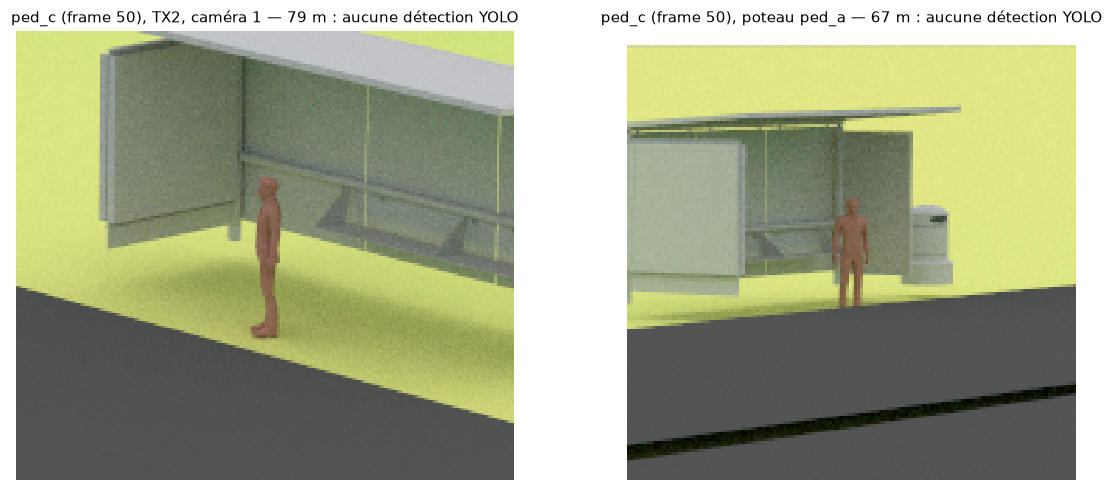

In [14]:
if STEP1:
    from PIL import Image as PILImage
    crops = [("frame_050_tx2_1.png", (742, 470, 942, 650), "TX2, caméra 1 — 79 m"),
             ("frame_050_ped_a_0.png", (779, 371, 939, 531), "poteau ped_a — 67 m")]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, (f, box, title) in zip(axes, crops):
        p = E1 / "frames" / f
        if p.exists():
            ax.imshow(PILImage.open(p).crop(box), interpolation="nearest")
        ax.set_title(f"ped_c (frame 50), {title} : aucune détection YOLO", fontsize=10)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

### 3.3 YOLO v3 : détecteur ré-entraîné avec le mobilier urbain

Le détecteur de la phase 3 (v2 : 2 classes, 240 images d'une scène sans mobilier, 320 px) rate les
piétons devant le mobilier et ne connaît pas le bus. Un v3 a été entraîné **sans utiliser la séquence
de test** (`code/yolo_v3_donnees.py`, `code/yolo_v3_entrainement.py`) :

- 1 300 rendus de la scène réelle, acteurs placés au hasard dans les rues (35 % des piétons à côté
  du mobilier), jamais sur les positions de test des piétons immobiles ; caméras aux mêmes points
  de montage que le déploiement mais visées et contenus différents ;
- étiquettes automatiques (sommets visibles de chaque acteur projetés dans l'image) ;
- 3 classes (car, pedestrian, bus), 960 px, 60 époques à partir du v2.

Validation (200 images du même générateur) : mAP50 0,978 (car 0,983, pedestrian 0,979, bus 0,973).
Le vrai test est la séquence de 100 frames, jamais vue : mêmes rendus et même radar que la section 3,
seules les détections changent.

,détecté v2,détecté v3,bien classé v2,bien classé v3,erreur v2 [m],erreur v3 [m]
acteur,,,,,,
bus,94%,99%,0%,99%,1.18,1.20
car,91%,91%,91%,91%,0.39,0.40
car2,75%,75%,75%,75%,0.82,0.82
ped_a,100%,100%,100%,100%,0.21,0.09
ped_b,81%,81%,81%,81%,0.20,0.02
ped_c,0%,82%,0%,82%,–,0.03
ped_d,54%,100%,10%,100%,0.63,0.34
ped_e,82%,82%,75%,82%,0.41,0.27


,C1,C2,C3,C4
faux objets / frame v2,0.07,0.13,0.14,0.14
faux objets / frame v3,0.07,0.13,0.14,0.14


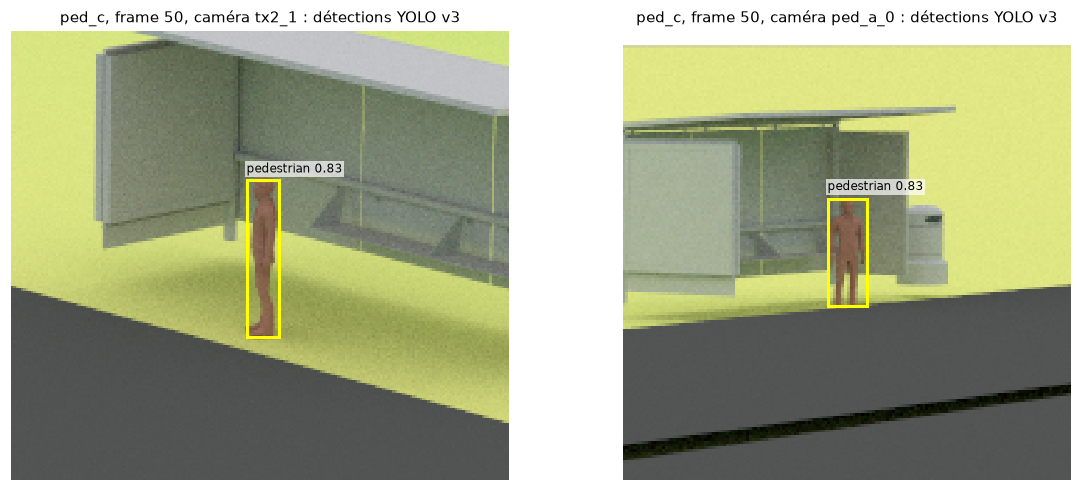

In [15]:
if STEP1 and STEP1_V3:
    r2, r3 = S1["resultats_couche_dynamique"], S1v3["resultats_couche_dynamique"]
    rows = []
    for a in r2["C4_FR1+FR2+vision"]["acteurs"]:
        m2, m3 = r2["C4_FR1+FR2+vision"]["acteurs"][a], r3["C4_FR1+FR2+vision"]["acteurs"][a]
        rows.append({"acteur": a, "détecté v2": m2["detecte"][0], "détecté v3": m3["detecte"][0],
                     "bien classé v2": m2["bien_classe"][0], "bien classé v3": m3["bien_classe"][0],
                     "erreur v2 [m]": m2["erreur_moyenne_m"][0], "erreur v3 [m]": m3["erreur_moyenne_m"][0]})
    fmt = {c: "{:.0%}" for c in ("détecté v2", "détecté v3", "bien classé v2", "bien classé v3")}
    fmt.update({c: "{:.2f}" for c in ("erreur v2 [m]", "erreur v3 [m]")})
    display(pd.DataFrame(rows).set_index("acteur").style.format(fmt, na_rep="–")
            .set_caption("Configuration C4 (FR1 + FR2 + vision) : YOLO v2 vs v3"))
    display(pd.DataFrame({c.split("_")[0]: {"faux objets / frame v2": f"{r2[c]['faux_objets_par_frame'][0]:.2f}",
                                            "faux objets / frame v3": f"{r3[c]['faux_objets_par_frame'][0]:.2f}"}
                          for c in r2}))
    # ped_c devant l'abribus, frame 50 : detections v2 (aucune) et v3
    from PIL import Image as PILImage
    from matplotlib.patches import Rectangle
    det3 = json.load(open(E1 / "cache" / "detections_yolo_v3.json"))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, (f, cam, box) in zip(axes, (("frame_050_tx2_1.png", "tx2_1", (742, 470, 942, 650)),
                                        ("frame_050_ped_a_0.png", "ped_a_0", (779, 371, 939, 531)))):
        ax.imshow(PILImage.open(E1 / "frames" / f).crop(box), interpolation="nearest")
        for d in det3["50"].get(cam, []):
            x0, y0, x1, y1 = d["bbox_xyxy"]
            if x1 > box[0] and x0 < box[2] and y1 > box[1] and y0 < box[3]:
                ax.add_patch(Rectangle((x0 - box[0], y0 - box[1]), x1 - x0, y1 - y0, fill=False,
                                       color={"car": "red", "pedestrian": "yellow", "bus": "cyan"}[d["cls"]], lw=2))
                ax.text(x0 - box[0], y0 - box[1] - 3, f"{d['cls']} {d['conf']:.2f}", color="k", fontsize=8,
                        bbox=dict(fc="w", ec="none", alpha=0.7, pad=1))
        ax.set_title(f"ped_c, frame 50, caméra {cam} : détections YOLO v3", fontsize=10)
        ax.axis("off")
    fig.tight_layout()
    plt.show()
elif STEP1:
    print("YOLO v3 pas encore evalue (etape1_jumeau_sequence.py --yolo ... --imgsz 960 --tag _yolo_v3).")

**Lecture.** Le v3 règle les trois défauts de la vision, sans ajouter de faux objets (0,14 par frame
dans les deux cas) :
- **ped_c** passe de 0 % à 82 % : il est maintenant reconnu devant l'abribus (confiance 0,83 sur les
  deux caméras ci-dessus). Il ne manque qu'à partir de **8,1 s**, quand le bus arrive à l'arrêt et le
  masque — c'est-à-dire exactement au moment où ses liens radio sont coupés (section 2.5). Le bus, lui,
  est vu et classé (99 %) et la dernière position de ped_c est connue : un suivi qui maintient la piste
  pendant le masquage (étape 5) peut anticiper ce blocage.
- **ped_d**, lointain, passe de 10 % à 100 % bien classé (inférence en 960 px au lieu de 640).
- **Le bus** est maintenant classé (0 % → 99 %) : le jumeau sait qu'il s'agit d'un objet de 11 m × 3 m,
  information directement utile pour prédire les blocages.
- L'erreur de position des piétons baisse aussi (ped_e 0,41 → 0,27 m, ped_d 0,63 → 0,34 m).
- Restent inchangés : la voiture perdue de 4,2 à 5,2 s et ped_b de 6,5 à 8,4 s pendant les passages
  du bus (masquage, pas un problème de détecteur).

## 4. Lien entre les deux étapes : pointer vers la position estimée par le jumeau

Première mesure de ce que coûte l'imperfection du jumeau au beamforming, sans encore aucun
prédicteur. Pour chaque UE et chaque frame :

1. on prend l'objet du jumeau le plus proche de l'acteur (à moins de 3 m) — l'association
   objet ↔ UE est supposée connue ici ;
2. on pointe le faisceau de la BS optimale vers cette position (hauteur de l'antenne supposée connue) ;
3. si l'acteur est absent du jumeau, on garde le dernier faisceau calculé ;
4. on compare au meilleur faisceau, avec les gains $G_b$ de l'étape 2.

Référence : le même faisceau géométrique calculé avec la **vraie** position (section 2.7).

,pas de faisceau,perte médiane [dB],≤ 1 dB,≤ 3 dB,> 10 dB (ou pas de faisceau)
pointage,,,,,
position vraie (J0),0%,0.0,98%,98%,1%
jumeau C1,75%,0.0,19%,20%,79%
jumeau C2,32%,0.0,63%,65%,34%
jumeau C3,32%,0.0,64%,65%,34%
jumeau C4,18%,0.0,79%,80%,19%
jumeau C4 + YOLO v3,4%,0.0,92%,93%,6%


,acteur absent (faisceau gardé)
référence,
C1_FR1,80%
C2_FR2,52%
C3_FR1+FR2,53%
C4_FR1+FR2+vision,32%
C4_FR1+FR2+vision + YOLO v3,13%


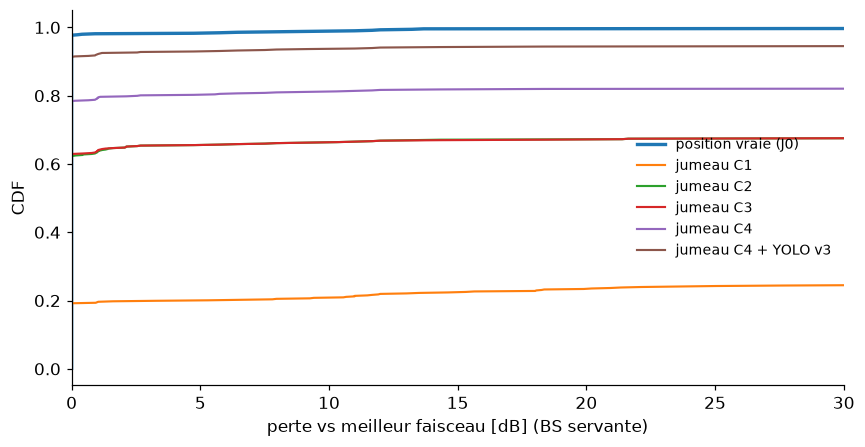

In [16]:
if STEP1:
    rot = R2["bs_rot"]; bs_pos = R2["bs_pos"]; ue_pos = R2["ue_pos"]          # [T, UE, 3]

    def beam_to(i, p):
        k = rot[i].T @ ((p - bs_pos[i]) / np.linalg.norm(p - bs_pos[i]))
        return -1 if k[0] <= 0 else int(np.argmin(np.sum((UV - k[1:]) ** 2, axis=1)))

    def twin_beam_loss(cfg, trial=0, J=None):
        tw = (J or J1)["jumeau"][cfg][trial]
        L = np.full((T, U), np.nan); hold = [None] * U; miss = np.zeros((T, U), bool)
        for t in range(T):
            objs = np.array([o["xy"] for o in tw[t]]).reshape(-1, 2)
            for j, a in enumerate(UES):
                i = BEST_BS[t, j]
                truth = gxy[t, names.index(a)]
                d = np.linalg.norm(objs - truth, axis=1) if len(objs) else np.array([np.inf])
                if d.min() <= 3.0:
                    p = np.r_[objs[d.argmin()], ue_pos[t, j, 2]]
                    hold[j] = beam_to(i, p)
                else:
                    miss[t, j] = True
                b = hold[j]
                if b is None or b < 0:
                    L[t, j] = np.inf
                else:
                    L[t, j] = 10 * np.log10(G[t, i, j].max() / max(G[t, i, j, b], 1e-30))
        return L, miss

    L_true = np.array([[loss[t, BEST_BS[t, j], j] for j in range(U)] for t in range(T)])
    rows, curves = [], {"position vraie (J0)": L_true[1:]}
    for cfg in J1["configs"]:
        L, miss = twin_beam_loss(cfg)
        curves[f"jumeau {cfg.split('_')[0]}"] = L[1:]
        rows.append({"référence": cfg, "acteur absent (faisceau gardé)": f"{miss[1:].mean():.0%}"})
    if STEP1_V3:
        c4 = "C4_FR1+FR2+vision"
        L, miss = twin_beam_loss(c4, J=J1v3)
        curves["jumeau C4 + YOLO v3"] = L[1:]
        rows.append({"référence": c4 + " + YOLO v3", "acteur absent (faisceau gardé)": f"{miss[1:].mean():.0%}"})
    summ = []
    for lab, L in curves.items():
        f = np.isfinite(L)
        summ.append({"pointage": lab, "pas de faisceau": f"{(~f).mean():.0%}",
                     "perte médiane [dB]": np.median(L[f]), "≤ 1 dB": f"{(L <= 1).mean():.0%}",
                     "≤ 3 dB": f"{(L <= 3).mean():.0%}",
                     "> 10 dB (ou pas de faisceau)": f"{(L > 10).mean():.0%}"})
    display(pd.DataFrame(summ).set_index("pointage"))
    display(pd.DataFrame(rows).set_index("référence"))
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for lab, L in curves.items():
        x = np.sort(np.minimum(L.ravel(), 40))
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), lw=2.2 if "vraie" in lab else 1.4, label=lab)
    ax.set(xlim=(0, 30), xlabel="perte vs meilleur faisceau [dB] (BS servante)", ylabel="CDF")
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()
    plt.show()

## 5. Conclusions

### Étape 2 — canal réel
- **La vérité terrain est validée.** En ligne de vue, le faisceau géométrique est à moins de 1 dB du
  meilleur dans 98 % des cas (convention de phase correcte) ; avec une autre graine pour la diffusion
  diffuse, le meilleur faisceau est le même dans 96 % des cas (écart de gain médian 0,07 dB).
- **Un défaut de Sionna a été trouvé et corrigé** : des réflexions comptées jusqu'à 8 fois sur des
  surfaces lointaines (bus surtout), qui gonflaient le gain de 5 à 16 dB sur ~1 % des liens et
  créaient de faux « meilleurs » liens (ped_c → TX1 à +15 dB). Le premier calcul est conservé dans
  `etape2_v0_avec_doublons/` pour comparaison.
- **Le scénario n'est pas limité par le SNR** : 30 à 43 dB sur la meilleure BS, aucune coupure. Avec
  5 BS en toiture, chaque UE garde presque toujours une BS en ligne de vue. L'enjeu pour les étapes
  suivantes n'est donc pas d'éviter des coupures mais de **perdre le moins de dB possible** en
  choisissant faisceau et BS sans balayage exhaustif — c'est la métrique à retenir (perte vs oracle,
  et nombre de faisceaux testés).
- **Les événements voulus sont présents** : le bus coupe 3 BS sur 4 utiles pour ped_c (−20 à −25 dB)
  et force un changement de BS ; la voiture et car2 changent de faisceau 9 et 5 fois en 10 s ; ped_d
  change de BS au coin.
- **La BS « oracle » scintille** entre BS quasi égales (ped_c : 25 changements en 10 s, et une 2e BS
  à moins de 1 dB de la meilleure dans 57 % des frames). Une règle d'hystérésis de 3 dB ramène cela à 0–3 changements par UE pour moins de
  3 dB de perte : c'est cette référence qu'il faudra utiliser pour évaluer la prédiction de handover.
- **J0 (pointer vers la vraie position)** est quasi optimal en ligne de vue (perte médiane 0 dB) mais
  perd 19 dB en médiane hors ligne de vue : c'est là que le jumeau doit apporter quelque chose.

### Étape 1 — jumeau par frame
- **La chaîne de la phase 5 tient sur une séquence longue et multi-acteurs** avec caméras fixes et
  confirmation causale : 0,14 faux objet par frame (C4), erreur de position 0,2 à 0,8 m pour les
  acteurs détectés (1,2 m pour le bus).
- **Chaque modalité a son rôle, comme en phase 5.** FR1 seul ne voit que les véhicules (voiture 90 %,
  aucun piéton). FR2 ajoute les piétons en mouvement (ped_a 63 %, ped_e 53 %). La vision (C4) est la
  seule à voir les piétons **immobiles** (ped_b 81 %) et porte ped_a à 100 % et ped_e à 82 %.
- **Avec le détecteur de la phase 3 (v2), trois limites nettes** : un piéton immobile devant du
  mobilier n'existe pas pour le jumeau (ped_c, 0 %) ; un piéton loin de toute caméra est vu mais pas
  classé (ped_d, 10 %) ; le bus est détecté mais jamais classé.
- **Le détecteur ré-entraîné (v3) les lève**, évalué sur la séquence jamais vue : ped_c 82 %, ped_d
  100 % bien classé, bus 99 % classé, sans faux objet supplémentaire. Ce qui reste manquant relève du
  **masquage** par le bus (voiture 4,2–5,2 s, ped_b 6,5–8,4 s, ped_c après 8,1 s), pas de la détection.

### Lien entre les étapes
- **Quand le jumeau voit l'UE, sa position suffit pour choisir le faisceau** : avec C4, 79 % des
  couples UE–frame sont à moins de 1 dB du meilleur faisceau (v2), **92 % avec YOLO v3**, contre 98 %
  avec la position vraie. L'erreur de 0,2 à 0,8 m est petite devant la largeur d'un faisceau (environ 10 m à 80 m).
- **Le facteur limitant est la détection, pas la précision** : avec v2, 18 % des couples n'ont jamais eu de
  faisceau (ped_c pendant toute la séquence, 14 %, et quelques UE avant leur première détection). Avec v3, ce n'est plus que 4 % ; C1 (FR1 seul) n'en donne un que pour 25 % des couples.
- Pour l'étape 3 (scène du jumeau, M2) et l'étape 4 (prédicteur + top-K) : (1) prévoir un repli quand
  l'UE n'est pas dans le jumeau (balayage partiel, ou dernière position connue + mouvement) ; (2) les
  pertes hors ligne de vue (19 dB pour J0) ne seront réduites que par la prise en compte de la
  propagation dans la scène du jumeau.

### Limites connues
- Le radar de l'étape 1 utilise le même solveur : il peut contenir quelques échos dupliqués sur des
  surfaces lointaines (comme en phase 5). Cela multiplie des points bruités au même endroit sans changer
  le filtre « deux points de vue » ; le dédoublonnage pourra être ajouté au radar si besoin.
- Les acteurs avancent à vitesse constante (pas d'accélération ni d'arrêt progressif).